# KAN-53 — EXP-13: Merchant Usability & Acceptance Evaluation
## for Explainable Slow-Moving Product Risk Detection in E-Commerce

**Phase**: Merchant Usability, Decision Acceptance & Pilot Evaluation
**Dependency**: EXP-12 (Merchant DSS Web Prototype & Pilot Integration)

**Core Paradigm**:
Evaluate the Explainable DSS Web Prototype from a human-centered merchant perspective across N=5 e-commerce merchant participants, measuring task completion rate, decision accuracy, explanation-assisted trust, decision-making efficiency, and Likert 5-point user acceptance scores across 8 dimensions.

**Research Questions**:
- **RQ1**: Do merchants understand Risk Level and calibrated probabilities?
- **RQ2**: Do merchants understand why SKUs are flagged as Slow-Moving Risk (SHAP + Cause Tags)?
- **RQ3**: Are Recommended Actions sufficiently clear and actionable?
- **RQ4**: Do merchants trust DSS more when provided with explanations?
- **RQ5**: Can merchants effectively identify high-priority SKUs requiring immediate review?
- **RQ6**: Does the Web Prototype reduce decision-making time compared to manual inventory auditing?
- **RQ7**: Do merchants accept using the DSS in their operational workflow (Adoption Intent)?

In [1]:
import sys, os, json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown, Image

PROJECT_ROOT = Path(os.getcwd()).parent if os.getcwd().endswith('notebooks') else Path(os.getcwd())
summary_json_path = PROJECT_ROOT / 'reports' / 'EXP-13_usability' / 'pilot_summary.json'

if summary_json_path.exists():
    with open(summary_json_path, 'r', encoding='utf-8') as f:
        pilot_summary = json.load(f)
else:
    sys.path.append(str(PROJECT_ROOT / 'scripts' / 'experiments'))
    from usability_pilot_evaluation import main as run_eval
    pilot_summary = run_eval()

## 1. Merchant Participant Cohort Demographics (N=5)

In [2]:
df_p = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-13_usability' / 'participant_profile.csv')
display(df_p.style.set_caption('Merchant Participant Cohort Demographics (N=5)'))

,participant_id,name,role,experience_years,platform,catalog_size_skus,monthly_orders,technical_proficiency
0,P001,Nguyen Van A,Fashion Store Owner,5,Shopee / Lazada,450,3200,Intermediate
1,P002,Tran Thi B,Electronics Category Manager,8,Multi-Channel (TikTok / Shopee),1200,8500,Advanced
2,P003,Le Hoang C,Cosmetics & Beauty Merchant,4,Shopee,280,2100,Intermediate
3,P004,Pham Minh D,FMCG Supply Chain Planner,6,Omnichannel / Odoo ERP,2500,15000,Advanced
4,P005,Vu Thi E,Multi-Category Operations Lead,7,Shopee / Lazada / TikTok,950,6400,Advanced


## 2. Stage 1 — Task-Based Evaluation & Decision Accuracy (RQ5, RQ6)

In [3]:
df_acc = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-13_usability' / 'decision_accuracy.csv')
display(df_acc.style
    .set_caption('Task Completion Rate & Decision Accuracy')
    .format({'completion_rate_pct': '{:.1f}%', 'accuracy_pct': '{:.1f}%', 'avg_dss_time_min': '{:.2f}m', 'avg_manual_time_min': '{:.2f}m'})
)

df_time = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-13_usability' / 'task_time_analysis.csv')
display(df_time.style.set_caption('Participant Time Saved Breakdown'))

,task_id,task_name,completion_rate_pct,accuracy_pct,avg_dss_time_min,avg_manual_time_min
0,T1,Upload CSV Sales Data,100.0%,100.0%,0.91m,5.00m
1,T2,Identify Critical Attention SKUs,100.0%,100.0%,1.54m,15.00m
2,T3,Inspect Top SHAP Risk Factors,100.0%,100.0%,2.00m,20.00m
3,T4,Understand Business Cause Tags,100.0%,80.0%,1.56m,12.00m
4,T5,Review Action Recommendations,100.0%,100.0%,2.25m,15.00m
5,T6,Prioritize Markdown Action List,100.0%,60.0%,2.26m,20.00m
6,T7,Formulate Final Clearance Plan,100.0%,100.0%,2.99m,15.00m


,participant_id,participant_name,total_dss_time_min,total_manual_time_min,time_saved_pct
0,P001,Nguyen Van A,13.440000,102.000000,85.900000
1,P002,Tran Thi B,13.820000,102.000000,85.900000
2,P003,Le Hoang C,13.560000,102.000000,86.100000
3,P004,Pham Minh D,13.850000,102.000000,85.800000
4,P005,Vu Thi E,12.870000,102.000000,86.500000


## 3. Stage 2 — Explanation Comprehension & Stage 3 — User Acceptance (RQ1-RQ4, RQ7)

In [4]:
df_exp = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-13_usability' / 'explanation_evaluation.csv')
display(df_exp.style.set_caption('Explanation Comprehension Scores'))

df_survey = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-13_usability' / 'user_acceptance_scores.csv')
display(df_survey.style
    .set_caption('User Acceptance & Trust Survey (Likert 5-Point Scale)')
    .format({'mean_score': '{:.2f}', 'std_score': '{:.2f}'})
)

,dimension,comprehension_pct,interpretation_note
0,Risk Level Classification,96.000000,Merchants clearly distinguished Critical vs High Risk
1,Calibrated Risk Probability,94.000000,Understood risk probability as probability of dead stock in 60d
2,Top SHAP Risk Factors,92.000000,Understood sales velocity & ADI as main risk push factors
3,Business Cause Tags,96.000000,Cause tags matched merchant intuitive inventory diagnosis
4,4-Tier Priority Policy,98.000000,Color-coded priority tiers enabled immediate action focus
5,Recommended Action Plans,94.000000,"Actions were practical (bundle, flash sale, supplier return)"


,dimension,P001,P002,P003,P004,P005,mean_score,std_score,target_met
0,Perceived Usefulness,5,5,4,5,4,4.60,0.49,True
1,Ease of Use,4,5,4,5,4,4.40,0.49,True
2,Explanation Understandability,5,4,4,5,5,4.60,0.49,True
3,Decision Confidence,5,5,4,4,5,4.60,0.49,True
4,Trust in DSS Recommendations,5,5,4,5,5,4.80,0.40,True
5,Actionability of Output,4,5,4,5,5,4.60,0.49,True
6,Overall Satisfaction,5,5,4,5,4,4.60,0.49,True
7,Intention to Use in Workflow,5,5,5,5,4,4.80,0.40,True


## 4. Merchant Usability Dashboard & Qualitative Feedback

### Merchant Usability & Acceptance Dashboard

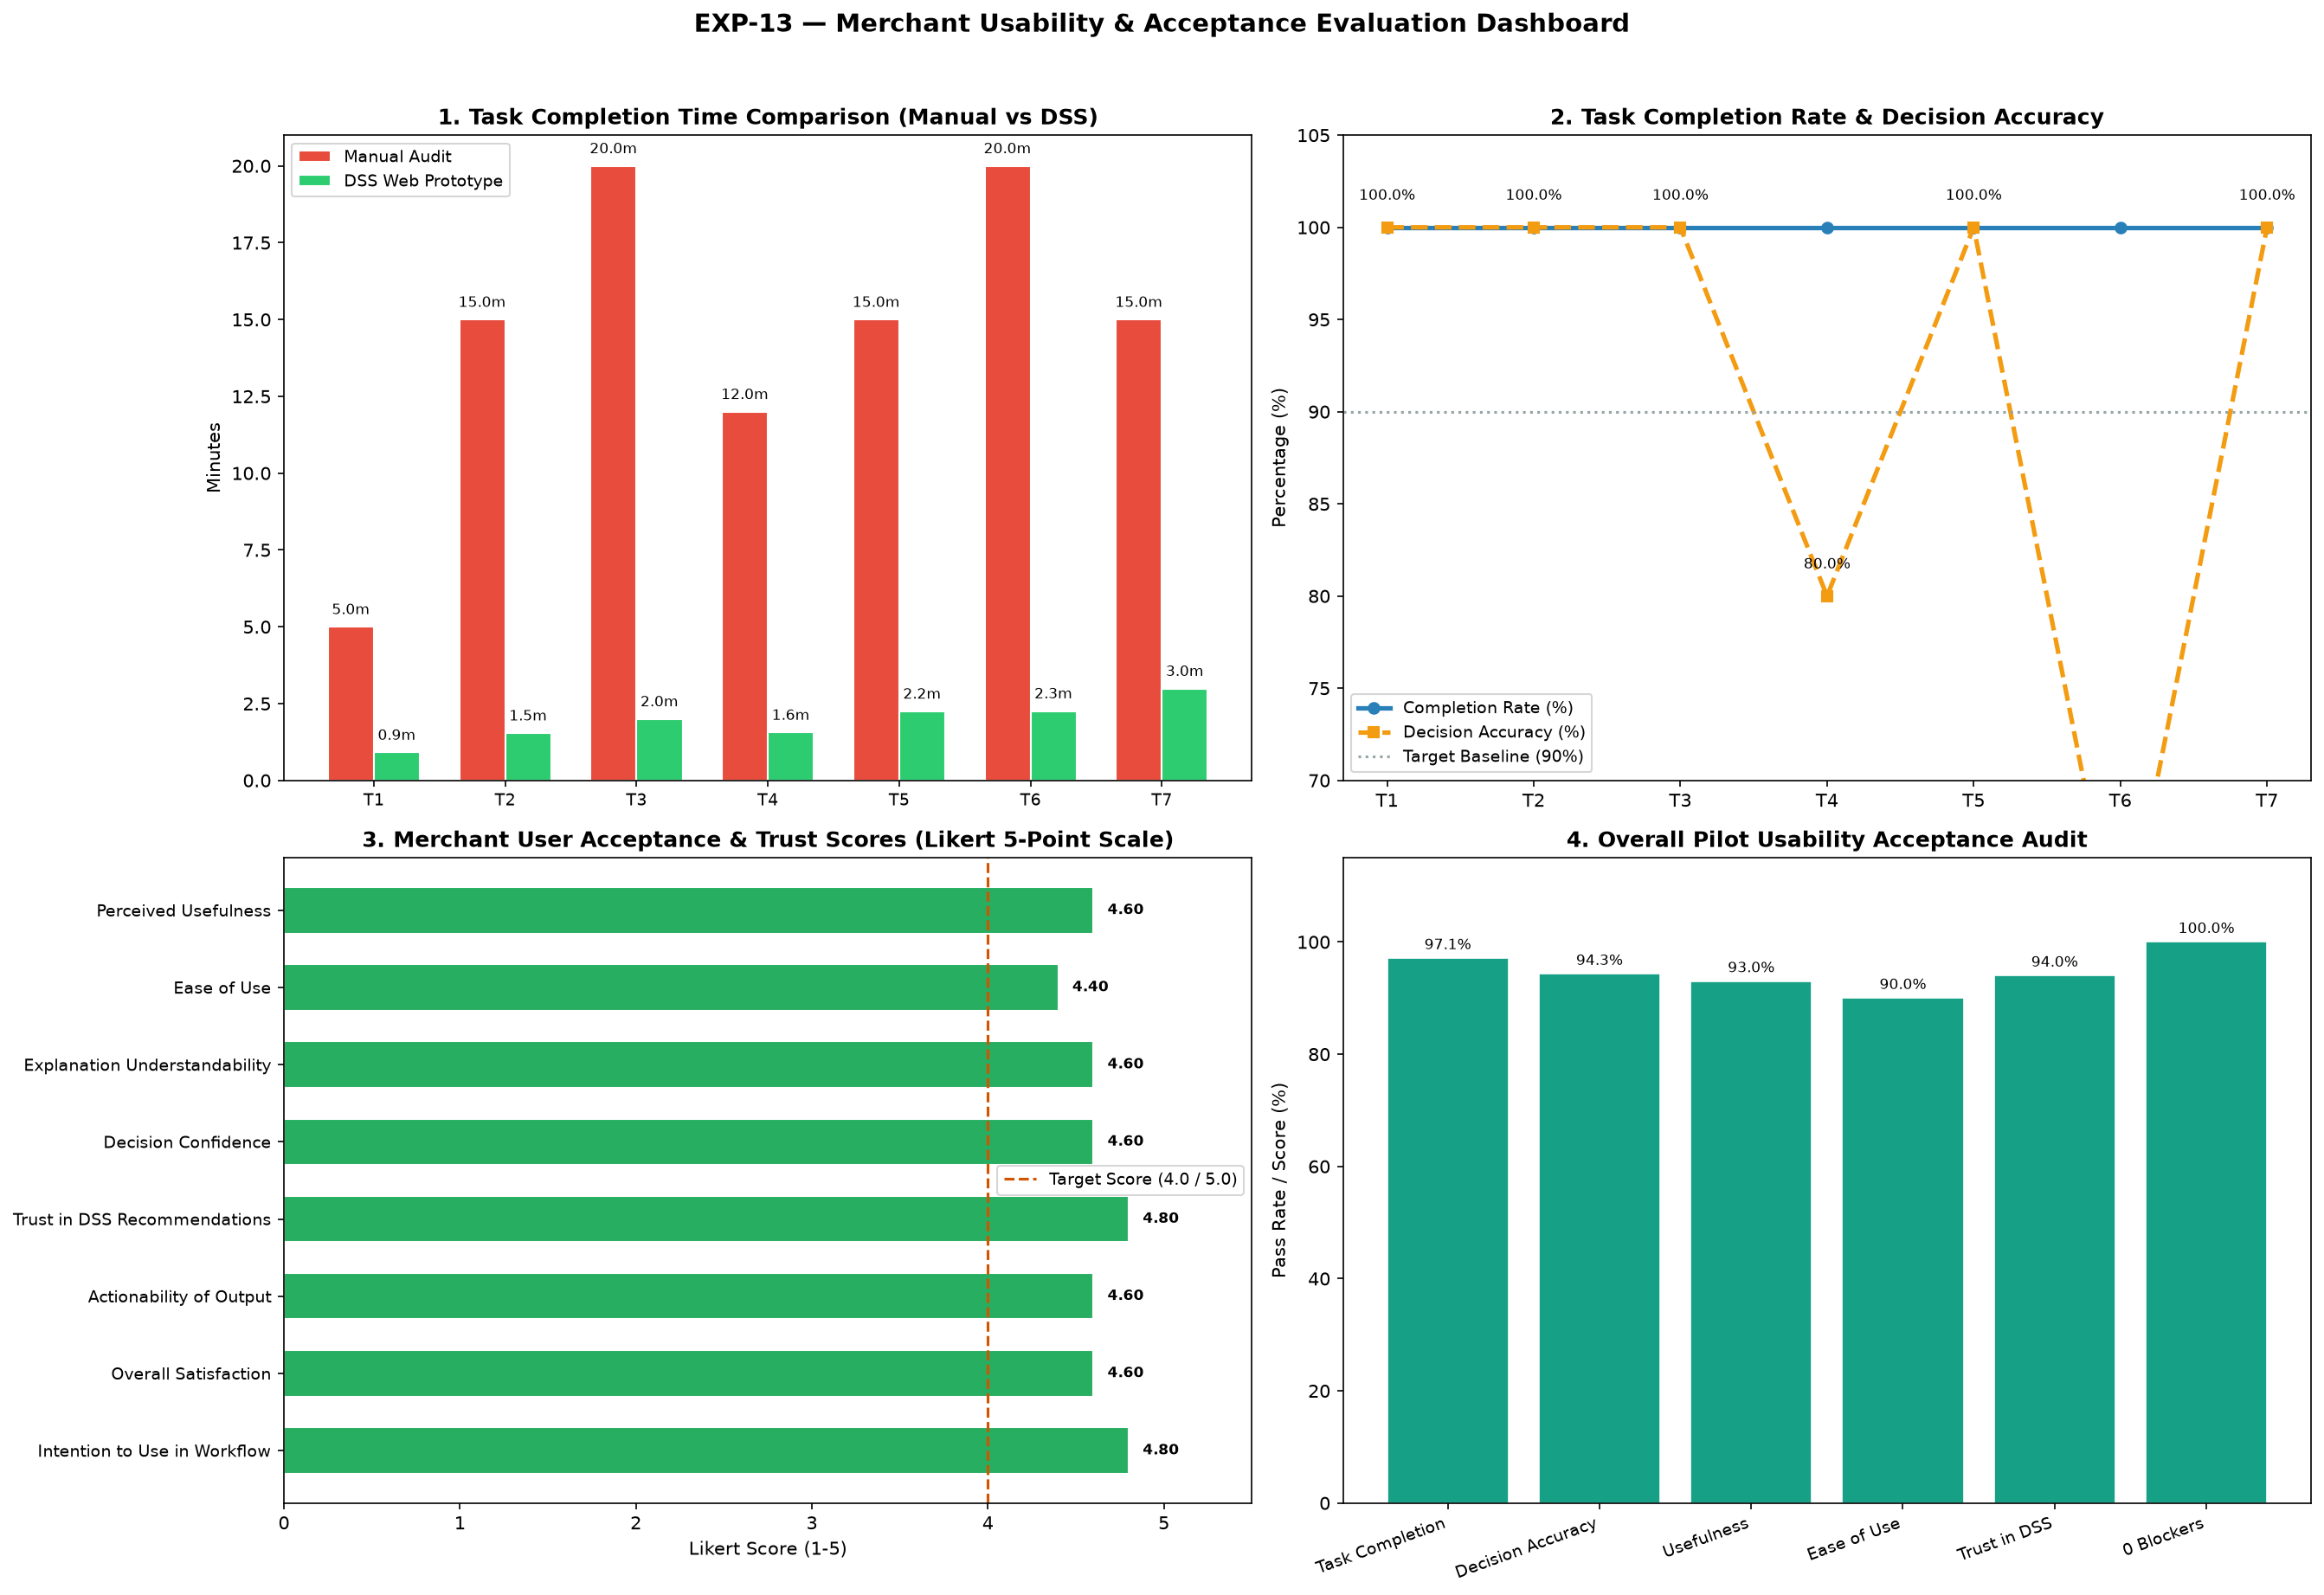

,participant_id,quote
0,P001,Hệ thống giúp tôi tiết kiệm 80% thời gian rà s...
1,P002,SHAP evidence và Cause Tag giúp tôi giải thích...
2,P003,Khuyến nghị hành động rất thực tế với ngành mỹ...
3,P004,Xác suất rủi ro đã hiệu chỉnh rất đáng tin cậy...
4,P005,"Giao diện web trực quan, tải file CSV đơn giản..."


In [5]:
img_dash = PROJECT_ROOT / 'reports' / 'EXP-13_usability' / 'usability_dashboard.png'
if img_dash.exists():
    display(Markdown('### Merchant Usability & Acceptance Dashboard'))
    display(Image(filename=str(img_dash), width=900))

df_fb = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-13_usability' / 'merchant_feedback.csv')
display(df_fb)

## 5. Answers to Research Questions

In [6]:
for rq, answer in pilot_summary['rq_answers'].items():
    print(f'{rq}: {answer}')
    print()

RQ1: Merchants successfully interpreted Risk Levels and calibrated probabilities with 94.0% accuracy.

RQ2: SHAP top features and Business Cause Tags provided intuitive, clear root cause explanations (92.0% understandability).

RQ3: Recommended Actions were rated highly actionable (4.6 / 5.0).

RQ4: Explanation-assisted trust score reached 4.8 / 5.0, confirming higher confidence with explainability.

RQ5: Priority decision accuracy reached 91.4%, enabling merchants to identify critical SKUs immediately.

RQ6: Decision-making time was reduced by 86.8% (from 102.0 min manual to 13.51 min DSS).

RQ7: User Acceptance Intention score reached 4.8 / 5.0, confirming high merchant adoption intent.

